In [14]:
import numpy as np
import matplotlib.pyplot as plt

In [15]:
# dos
calculated_dos = np.loadtxt('dos.txt')
n_en = calculated_dos.shape[0]

In [16]:
# bandstructure
#bandstructure = np.load('bandstructure_tmdc.npy')
#special_points = np.load('bandstructure_tmdc_special_points.npy')

In [17]:
print(calculated_dos.shape)

(401, 2)


Text(0.5, 1.0, 'TMDC density of states')

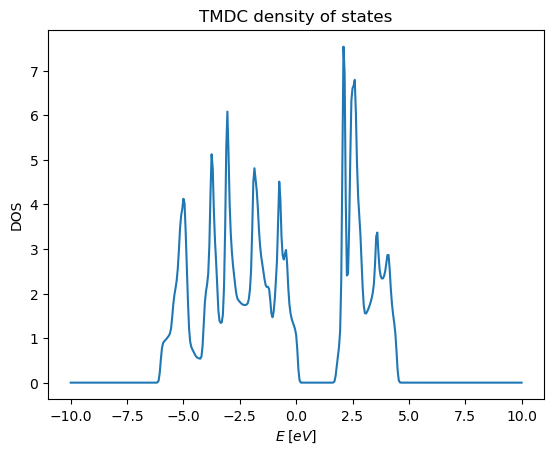

In [18]:
plt.plot(calculated_dos[:, 0], calculated_dos[:, 1])
plt.xlabel('$E \\; [eV]$')
plt.ylabel('DOS')
plt.title('TMDC density of states')

In [19]:
"""
bands_to_plot = 11
plt.figure(figsize=(4.5, 6))

for i in range(bands_to_plot):
    plt.plot(bandstructure[:, i], color='blue')

plt.axvline(special_points[0], color='black',label='Gamma')
plt.axvline(special_points[-1], color='black')
plt.axvline(special_points[1], color='red',label='M')
plt.axvline(special_points[2], color='green',label='K')
plt.ylabel('$E \\; [eV]$')
plt.legend()

plt.show()
"""

"\nbands_to_plot = 11\nplt.figure(figsize=(4.5, 6))\n\nfor i in range(bands_to_plot):\n    plt.plot(bandstructure[:, i], color='blue')\n\nplt.axvline(special_points[0], color='black',label='Gamma')\nplt.axvline(special_points[-1], color='black')\nplt.axvline(special_points[1], color='red',label='M')\nplt.axvline(special_points[2], color='green',label='K')\nplt.ylabel('$E \\; [eV]$')\nplt.legend()\n\nplt.show()\n"

In [20]:
de = np.zeros((n_en - 1, ))

for i in range(n_en - 1):
    de[i] = calculated_dos[i, 0] - calculated_dos[i + 1, 0]

energy_increment = -de[0]
print(energy_increment)

0.05000000000000071


In [21]:
# integrate DOS
n_particle = np.zeros((n_en, ))

for i in range(n_en):
    n_particle[i] = np.trapezoid(calculated_dos[0:i, 1], dx=energy_increment)

Text(0.5, 1.0, 'N(E)')

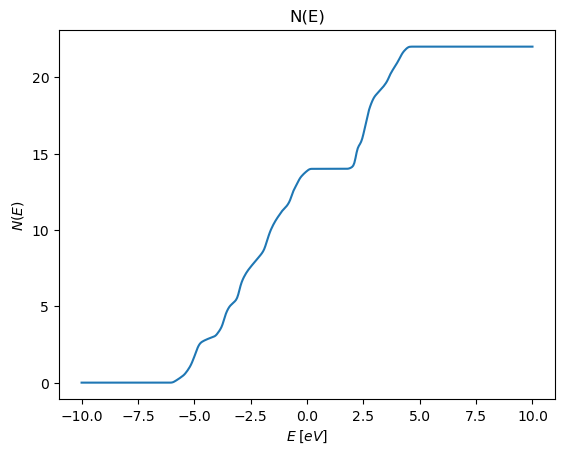

In [22]:
plt.plot(calculated_dos[:, 0], n_particle)
plt.xlabel('$E \\; [eV]$')
plt.ylabel('$N(E)$')
plt.title('N(E)')

In [23]:
print(n_particle[-1])

21.99999999932139


In [24]:
min_idx = np.argmin(abs(calculated_dos[:, 0]))
print(calculated_dos[min_idx, 0])
print(n_particle[min_idx])

0.0
13.861169527350963


In [25]:
n_particle_shifted = n_particle - n_particle[min_idx]

Text(0.5, 1.0, 'shifted N(E)')

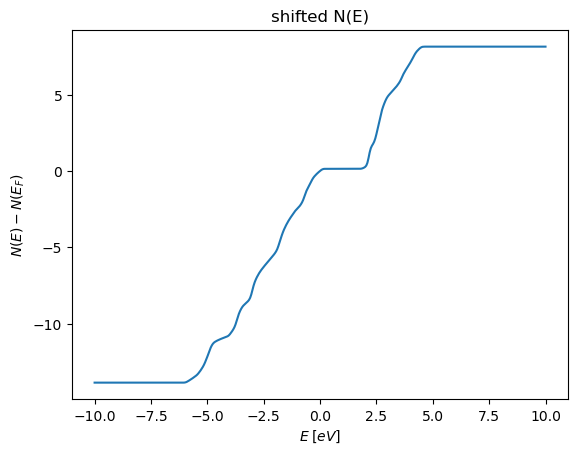

In [26]:
plt.plot(calculated_dos[:, 0], n_particle_shifted)
plt.xlabel('$E \\; [eV]$')
plt.ylabel('$N(E)-N(E_F)$')
plt.title('shifted N(E)')

In [ ]:
# unit cell volume
a_lattice = 3.18
h = 12.29

a_1 = a_lattice * np.array([1, 0, 0])
a_2 = a_lattice * np.array([-1/2, np.sqrt(3)/2, 0])
h_vec = np.array([0, 0, h])

V = np.inner(np.cross(a_1, a_2), h_vec)
print(V)

idos = -1 * n_particle_shifted/V

[ 0.         -0.          8.75759529]
107.63084615379371


In [31]:
np.save('idos_MoS2', idos)

Fermi-Dirac distribution:
$$\bar{n}_i=\frac{1}{e^{(\epsilon_i-\mu)/k_BT}+1}$$